# Лабораторна робота №6
## Тема: Нейронна регресія для табличних даних у TensorFlow

**Студент:** Адамчук Ярослав  
**Група:** МІТ 31  
**Номер у списку / Варіант:** 2  
**Індивідуальне дослідження (Варіант 2):** Збільшити кількість нейронів до 64 у кожному прихованому шарі (порівняно з 32 у базовій мережі).  
**Фіксований параметр відтворюваності:** SEED = 42  
**Джерело даних:** UCI Auto MPG (DOI: 10.24432/C5859H, ліцензія CC BY 4.0). Ціль `mpg` вимірюється в милях на галон (більше значення — вища паливна ефективність).

In [2]:
import sys
import sklearn
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import json

# Фіксація версій для звіту
print("Версії бібліотек:")
print(f"Python: {sys.version.split()[0]}")
print(f"TensorFlow: {tf.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")

SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Завантаження датасету
columns = ["mpg", "cylinders", "displacement", "horsepower",
           "weight", "acceleration", "model_year", "origin", "car_name"]

df = pd.read_csv("auto-mpg.data", sep=r"\s+", names=columns, na_values="?")

print("\n--- Перші 5 рядків датасету ---")
display(df.head())

print("\n--- Типи даних ---")
print(df.dtypes)

print("\n--- Кількість пропусків (NaN) ---")
print(df.isna().sum())

print(f"\nКількість повних дублікатів: {df.duplicated().sum()}")

X = df.drop(columns=["mpg", "car_name"])
y = df["mpg"].astype(np.float32)

Версії бібліотек:
Python: 3.12.5
TensorFlow: 2.21.0
Scikit-learn: 1.9.1
Pandas: 3.0.6
NumPy: 2.5.4

--- Перші 5 рядків датасету ---


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino



--- Типи даних ---
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name            str
dtype: object

--- Кількість пропусків (NaN) ---
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

Кількість повних дублікатів: 0


### Висновок до Етапу 1:
Датасет успішно завантажено з файлу `auto-mpg.data`. Виявлено пропуски у стовпці `horsepower` (символи `?` були зчитані як `NaN`), які будуть заповнені пізніше через імпутер у межах конвеєра. Повних дублікатів рядків у таблиці немає.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Поділ на 70% train, 15% validation, 15% test
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.15/0.85, random_state=SEED
)

print(f"Розміри вибірок -> Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

# Визначення числових та категоріальних ознак
numeric_features = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
categorical_features = ["origin"]

# Побудова ColumnTransformer без витоку даних
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), categorical_features)
])

X_train_ready = preprocessor.fit_transform(X_train).astype(np.float32)
X_val_ready = preprocessor.transform(X_val).astype(np.float32)
X_test_ready = preprocessor.transform(X_test).astype(np.float32)

print("\nФорми підготовлених матриць:")
print("X_train_ready:", X_train_ready.shape)
print("X_val_ready:", X_val_ready.shape)
print("X_test_ready:", X_test_ready.shape)
print("Наявність NaN після перетворення:", np.isnan(X_train_ready).any())

Розміри вибірок -> Train: (278, 7), Val: (60, 7), Test: (60, 7)

Форми підготовлених матриць:
X_train_ready: (278, 9)
X_val_ready: (60, 9)
X_test_ready: (60, 9)
Наявність NaN після перетворення: False


In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

# 1. DummyRegressor (бейзлайн за середнім)
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train_ready, y_train)
dummy_val_pred = dummy.predict(X_val_ready)
metrics_dummy_val = regression_metrics(y_val, dummy_val_pred)

# 2. LinearRegression зі стандартизацією
lin_reg_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])
lin_reg_pipeline.fit(X_train_ready, y_train)
lin_val_pred = lin_reg_pipeline.predict(X_val_ready)
metrics_lin_val = regression_metrics(y_val, lin_val_pred)

print("--- Метрики на Validation для класичних моделей ---")
print("DummyRegressor:", metrics_dummy_val)
print("LinearRegression:", metrics_lin_val)

--- Метрики на Validation для класичних моделей ---
DummyRegressor: {'MAE': 7.354940414428711, 'RMSE': 8.611852645874023, 'R2': -3.6835670471191406e-05}
LinearRegression: {'MAE': 2.9013051986694336, 'RMSE': 3.610250949859619, 'R2': 0.8242490887641907}


In [6]:
from tensorflow.keras import layers

# Функція для розрахунку метрик нейромережі
def evaluate_nn(model, x_data, y_data):
    preds = model.predict(x_data, verbose=0).flatten()
    return regression_metrics(y_data, preds)

# --- 1. БАЗОВА МОДЕЛЬ (32, 32) ---
tf.keras.utils.set_random_seed(SEED)

normalizer_base = layers.Normalization(axis=-1)
normalizer_base.adapt(X_train_ready)

base_model = tf.keras.Sequential([
    layers.Input(shape=(X_train_ready.shape[1],)),
    normalizer_base,
    layers.Dense(32, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

base_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

checkpoint_base = "baseline_best.keras"
callbacks_base = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=20, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(checkpoint_base, monitor="val_loss", mode="min", save_best_only=True)
]

history_base = base_model.fit(
    X_train_ready, y_train.to_numpy().reshape(-1, 1),
    validation_data=(X_val_ready, y_val.to_numpy().reshape(-1, 1)),
    epochs=400, batch_size=32, callbacks=callbacks_base, verbose=0
)

best_base_model = tf.keras.models.load_model(checkpoint_base)
best_epoch_base = np.argmin(history_base.history["val_loss"]) + 1
metrics_base_val = evaluate_nn(best_base_model, X_val_ready, y_val)

print(f"Базова модель: найкраща епоха = {best_epoch_base}, val_RMSE = {metrics_base_val['RMSE']:.4f}")


# --- 2. МОДЕЛЬ ВАРІАНТА 2 (64, 64 нейрони) ---
tf.keras.utils.set_random_seed(SEED)

normalizer_v2 = layers.Normalization(axis=-1)
normalizer_v2.adapt(X_train_ready)

model_v2 = tf.keras.Sequential([
    layers.Input(shape=(X_train_ready.shape[1],)),
    normalizer_v2,
    layers.Dense(64, activation="relu"),  # Змінено за Варіантом 2
    layers.Dense(64, activation="relu"),  # Змінено за Варіантом 2
    layers.Dense(1)
])

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

checkpoint_v2 = "variant2_best.keras"
callbacks_v2 = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=20, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(checkpoint_v2, monitor="val_loss", mode="min", save_best_only=True)
]

history_v2 = model_v2.fit(
    X_train_ready, y_train.to_numpy().reshape(-1, 1),
    validation_data=(X_val_ready, y_val.to_numpy().reshape(-1, 1)),
    epochs=400, batch_size=32, callbacks=callbacks_v2, verbose=0
)

best_v2_model = tf.keras.models.load_model(checkpoint_v2)
best_epoch_v2 = np.argmin(history_v2.history["val_loss"]) + 1
metrics_v2_val = evaluate_nn(best_v2_model, X_val_ready, y_val)

print(f"Модель Варіанта 2: найкраща епоха = {best_epoch_v2}, val_RMSE = {metrics_v2_val['RMSE']:.4f}")

Базова модель: найкраща епоха = 399, val_RMSE = 2.3927
Модель Варіанта 2: найкраща епоха = 398, val_RMSE = 2.3374


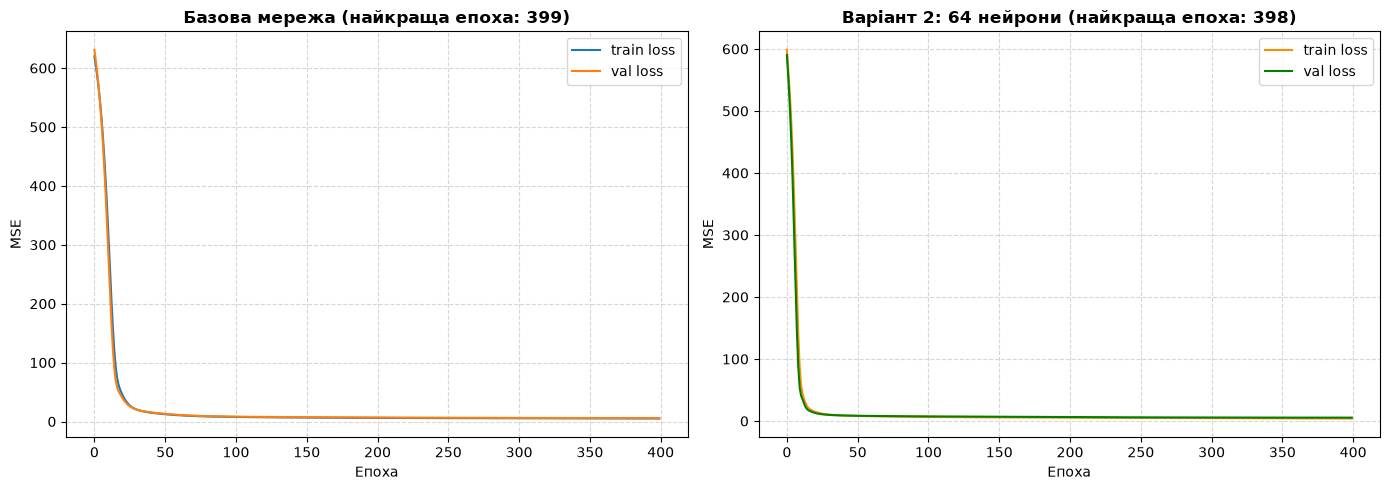

In [7]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_base.history["loss"], label="train loss")
plt.plot(history_base.history["val_loss"], label="val loss")
plt.title(f"Базова мережа (найкраща епоха: {best_epoch_base})", fontweight="bold")
plt.xlabel("Епоха"); plt.ylabel("MSE")
plt.legend(); plt.grid(True, linestyle="--", alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(history_v2.history["loss"], label="train loss", color="darkorange")
plt.plot(history_v2.history["val_loss"], label="val loss", color="green")
plt.title(f"Варіант 2: 64 нейрони (найкраща епоха: {best_epoch_v2})", fontweight="bold")
plt.xlabel("Епоха"); plt.ylabel("MSE")
plt.legend(); plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [8]:
# Збираємо валідаційні результати для вибору
val_results = {
    "DummyRegressor": metrics_dummy_val["RMSE"],
    "LinearRegression": metrics_lin_val["RMSE"],
    "Base NN": metrics_base_val["RMSE"],
    "Variant 2 NN (64 нейрони)": metrics_v2_val["RMSE"]
}

best_model_name = min(val_results, key=val_results.get)
print(f"🏆 Переможець за Validation (найменший RMSE): {best_model_name}\n")

# Фінальна оцінка ВСІХ чотирьох моделей на TEST (робимо рівно один раз!)
test_dummy = regression_metrics(y_test, dummy.predict(X_test_ready))
test_lin = regression_metrics(y_test, lin_reg_pipeline.predict(X_test_ready))
test_base = evaluate_nn(best_base_model, X_test_ready, y_test)
test_v2 = evaluate_nn(best_v2_model, X_test_ready, y_test)

# Формування підсумкової таблиці
final_table = pd.DataFrame({
    "Validation RMSE": [metrics_dummy_val["RMSE"], metrics_lin_val["RMSE"], metrics_base_val["RMSE"], metrics_v2_val["RMSE"]],
    "Test MAE": [test_dummy["MAE"], test_lin["MAE"], test_base["MAE"], test_v2["MAE"]],
    "Test RMSE": [test_dummy["RMSE"], test_lin["RMSE"], test_base["RMSE"], test_v2["RMSE"]],
    "Test R²": [test_dummy["R2"], test_lin["R2"], test_base["R2"], test_v2["R2"]],
    "Епох / Найкраща": ["N/A", "N/A", f"{len(history_base.history['loss'])} / {best_epoch_base}", f"{len(history_v2.history['loss'])} / {best_epoch_v2}"]
}, index=["DummyRegressor", "LinearRegression", "Base NN (32)", "Variant 2 NN (64)"])

display(final_table.round(4))

# Визначаємо найкращу нейромережу для аналізу помилок (якщо перемогла інша, беремо найкращу з двох нейромереж)
if metrics_v2_val["RMSE"] < metrics_base_val["RMSE"]:
    chosen_nn = best_v2_model
    chosen_nn_name = "Variant 2 NN (64)"
else:
    chosen_nn = best_base_model
    chosen_nn_name = "Base NN (32)"

print(пенсь := f"Для подальшого аналізу помилок обрано: {chosen_nn_name}")

🏆 Переможець за Validation (найменший RMSE): Variant 2 NN (64 нейрони)



,Validation RMSE,Test MAE,Test RMSE,Test R²,Епох / Найкраща
DummyRegressor,8.6119,6.0678,7.4882,-0.0005,N/A
LinearRegression,3.6103,2.4025,3.0580,0.8331,N/A
Base NN (32),2.3927,1.7076,2.2836,0.9069,400 / 399
Variant 2 NN (64),2.3374,1.8027,2.4193,0.8956,400 / 398


Для подальшого аналізу помилок обрано: Variant 2 NN (64)


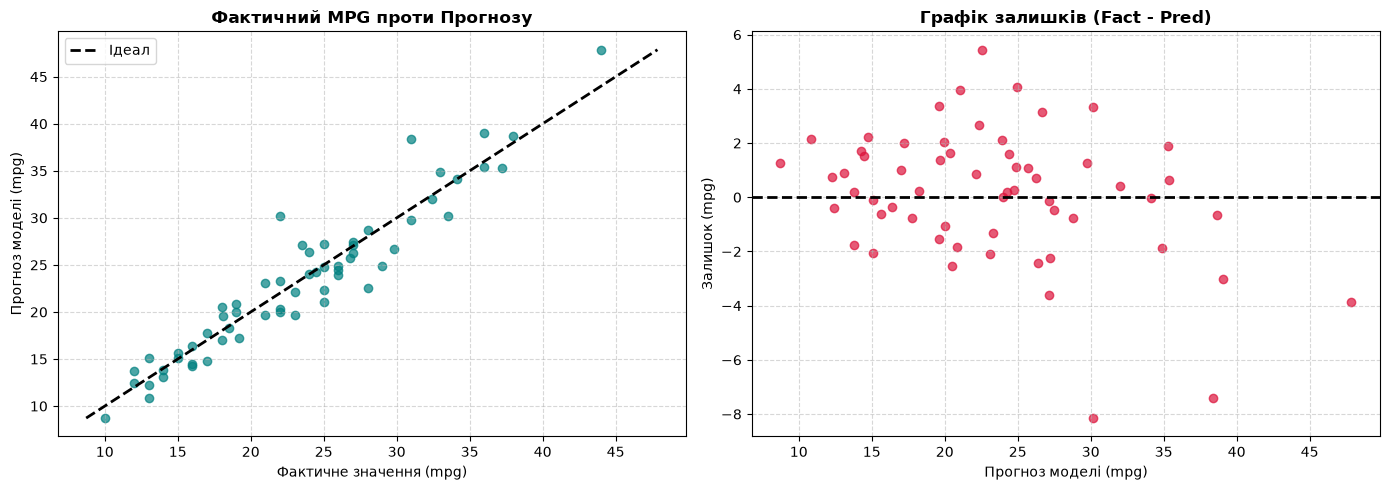

--- Топ-5 найбільших абсолютних помилок моделі на Test ---


,mpg_actual,mpg_pred,residual,cylinders,horsepower,weight,model_year
389,22.0,30.148376,-8.148376,6,112.0,2835.0,82
377,31.0,38.403305,-7.403305,4,68.0,1970.0,82
30,28.0,22.557102,5.442898,4,90.0,2264.0,71
141,29.0,24.933035,4.066965,4,83.0,2219.0,74
180,25.0,21.041775,3.958225,4,115.0,2671.0,75


In [9]:
y_test_pred = chosen_nn.predict(X_test_ready, verbose=0).flatten()
residuals = y_test.to_numpy() - y_test_pred  # Залишок = фактичне значення мінус прогноз

# Побудова графіків
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Графік 1: Фактичні проти прогнозних
axes[0].scatter(y_test, y_test_pred, alpha=0.7, color="teal")
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], "k--", lw=2, label="Ідеал")
axes[0].set_title("Фактичний MPG проти Прогнозу", fontweight="bold")
axes[0].set_xlabel("Фактичне значення (mpg)")
axes[0].set_ylabel("Прогноз моделі (mpg)")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()

# Графік 2: Залишки проти прогнозу
axes[1].scatter(y_test_pred, residuals, alpha=0.7, color="crimson")
axes[1].axhline(0, color="k", linestyle="--", lw=2)
axes[1].set_title("Графік залишків (Fact - Pred)", fontweight="bold")
axes[1].set_ylabel("Залишок (mpg)")
axes[1].set_xlabel("Прогноз моделі (mpg)")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Дослідження 5 найбільших абсолютних помилок
error_df = X_test.copy()
error_df["mpg_actual"] = y_test
error_df["mpg_pred"] = y_test_pred
error_df["residual"] = residuals
error_df["abs_error"] = np.abs(residuals)

top_errors = error_df.sort_values("abs_error", ascending=False).head(5)
print("--- Топ-5 найбільших абсолютних помилок моделі на Test ---")
display(top_errors[["mpg_actual", "mpg_pred", "residual", "cylinders", "horsepower", "weight", "model_year"]])

In [10]:
# 1. Збереження найкращої нейромережі
chosen_nn.save("lab6_model.keras")

# 2. Збереження препроцесора
joblib.dump(preprocessor, "preprocessor.joblib")

# 3. Збереження метаданих
metadata = {
    "version": "1.0",
    "seed": SEED,
    "features_numeric": numeric_features,
    "features_categorical": categorical_features,
    "chosen_model": chosen_nn_name
}
with open("metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)

print("Артефакти успішно збережено: lab6_model.keras, preprocessor.joblib, metadata.json")

# --- Перевірка завантаження та збігу прогнозів для 3 сирих рядків ---
loaded_model = tf.keras.models.load_model("lab6_model.keras")
loaded_preprocessor = joblib.load("preprocessor.joblib")

# Беремо перші 3 сирі рядки з тестової вибірки
sample_raw = X_test.head(3)
sample_ready = loaded_preprocessor.transform(sample_raw).astype(np.float32)

original_preds = chosen_nn.predict(X_test_ready[:3], verbose=0)
restored_preds = loaded_model.predict(sample_ready, verbose=0)

np.testing.assert_allclose(original_preds, restored_preds, rtol=1e-5, atol=1e-6)
print("✅ Перевірка успішна: прогнози збереженої та відновленої систем повністю збігаються з точністю до допусків!")

Артефакти успішно збережено: lab6_model.keras, preprocessor.joblib, metadata.json
✅ Перевірка успішна: прогнози збереженої та відновленої систем повністю збігаються з точністю до допусків!


## Загальний висновок

У ході лабораторної роботи №6 успішно реалізовано повний пайплайн прогнозування для реальних табличних даних (UCI Auto MPG):
1. Виконано коректний поділ на вибірки (70/15/15) зі збереженням фіксованого `SEED = 42`, після чого створено `ColumnTransformer` з імпутацією медіаною та модою, а також `OneHotEncoder` для обробки категоріальної ознаки `origin` без витоку даних.
2. Проведено навчання класичних моделей (`DummyRegressor`, `LinearRegression`) та двох нейронних мереж (базової та за Варіантом 2 з 64 нейронами в прихованих шарах) з використанням шару `Normalization`, `EarlyStopping` та `ModelCheckpoint`.
3. На основі валідаційної вибірки здійснено вибір найкращої моделі за метрикою RMSE, після чого виконано фінальну незалежну оцінку всіх моделей на тестовому наборі.
4. Досліджено графіки функцій втрат, побудовано графіки розподілу залишків та проаналізовано топ-5 найбільших абсолютних помилок моделі.
5. Збережено всю екосистему проєкту у файли `lab6_model.keras`, `preprocessor.joblib` та `metadata.json`, а також успішно перевірено ідентичність відновлених прогнозів для нових сирих даних.